In [1]:
import warnings
import itables
from itables import show
import pandas as pd
import matplotlib.pyplot as plt

# Suppress all categories of warnings globally 
warnings.filterwarnings("ignore")

data = pd.read_csv('/kaggle/input/competitions/name-that-llm/train.csv')
data.head()

,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash


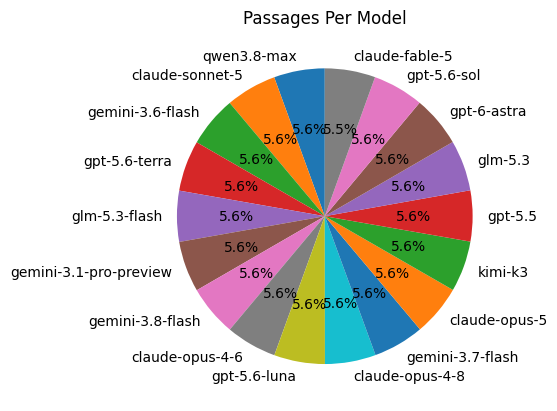

In [2]:
# Passages Per Model
data["model"].value_counts().plot(kind="pie", autopct="%1.1f%%", startangle=90)
plt.ylabel("")
plt.title("Passages Per Model")
plt.show()

In [3]:
# Word Count Per Passage, it's mean, min and max per model
wc = data[["model" , "text"]]
# Adding word-count per passage: 
wc["wc_per_passage"] = wc["text"].str.split().str.len()
display(wc.head())

# Text Summary 
resp_summary = (
    wc.groupby("model")["wc_per_passage"].agg(["mean", "max", "min"]).reset_index()
)
display(resp_summary.head(3))

,model,text,wc_per_passage
0,qwen3.8-max,"When a language dies, a particular astronomy d...",192
1,claude-sonnet-5,Data science communities matter because they a...,65
2,gemini-3.6-flash,"In the final twilight of time, the last embers...",77
3,gpt-5.6-terra,Data science communities matter because they t...,220
4,glm-5.3-flash,"Deep inside each ear, three tiny loops of bone...",97


,model,mean,max,min
0,claude-fable-5,112.496644,252,39
1,claude-opus-4-6,115.146667,274,42
2,claude-opus-4-8,123.593333,251,42


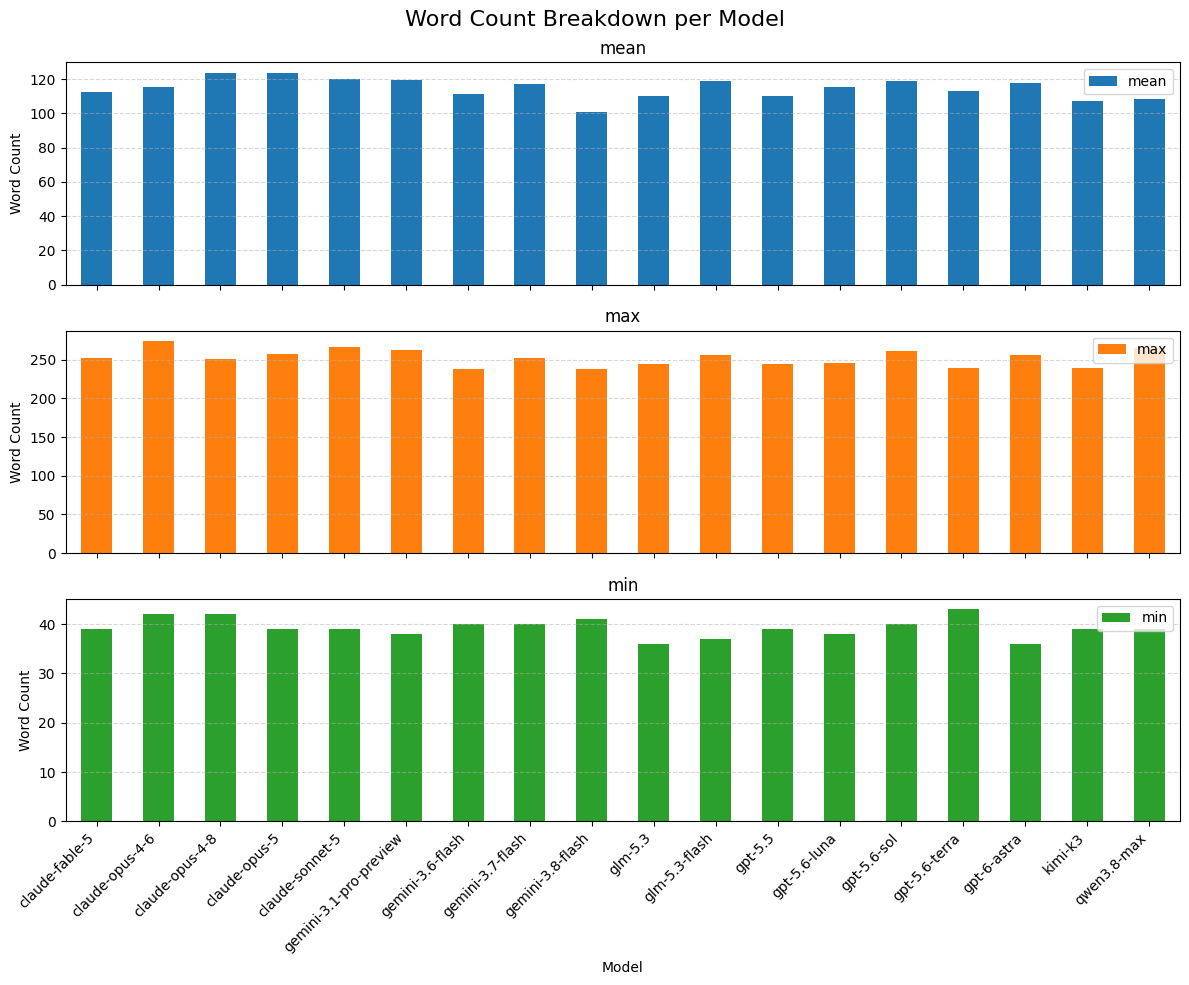

In [4]:
### Plotting the Word-Count  Breakdown
# 1. Use subplots=True to split 'mean', 'max', and 'min' into individual graphs
axes = resp_summary.plot(
    x="model",
    y=["mean", "max", "min"],
    kind="bar",
    subplots=True,  # Tells pandas to make separate plots
    figsize=(12, 10),  # Taller figure size to fit all 3 plots
    sharex=True,  # Ensures all 3 plots line up perfectly over the same X-axis
)

# 2. Loop through each individual axis to add labels/grids
for ax in axes:
    ax.set_ylabel("Word Count")
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.legend(loc="upper right")

# Rotate the labels on the very bottom graph so they read clearly
plt.xticks(rotation=45, ha="right")

plt.xlabel("Model")
plt.suptitle("Word Count Breakdown per Model", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

In [5]:
# 1. Choose 4 models from your dataset to inspect
# You can replace this list with specific sibling models if you see them in data['model'].unique()
selected_models = data["model"].value_counts().index[:].tolist()
print(f"Inspecting models: {selected_models}\n")

Inspecting models: ['qwen3.8-max', 'claude-sonnet-5', 'gemini-3.6-flash', 'gpt-5.6-terra', 'glm-5.3-flash', 'gemini-3.1-pro-preview', 'gemini-3.8-flash', 'claude-opus-4-6', 'gpt-5.6-luna', 'claude-opus-4-8', 'gemini-3.7-flash', 'claude-opus-5', 'kimi-k3', 'gpt-5.5', 'glm-5.3', 'gpt-6-astra', 'gpt-5.6-sol', 'claude-fable-5']



In [6]:
# 1. Select the top 4 models from your dataset
selected_models = data["model"].value_counts().index[:4].tolist()
print(f"Generating interactive tables for models: {selected_models}\n")

# 2. Loop through each model group
for model_name in selected_models:
    print("\n" + "=" * 60)
    print(f" 📂 RIGHT-ALIGNED TEXT VIEW: {model_name}")
    print("=" * 60)

    model_samples = data[data["model"] == model_name]
    sample_size = min(5, len(model_samples))
    sampled_df = model_samples.sample(n=sample_size, random_state=42)

    # Use columnDefs to right-align the text column (Target 2)
    show(
        sampled_df[["id", "text"]],
        classes="display nowrap compact",
        height="300px",
        maxBytes=0,
        paging=False,
        searching=True,
        columnDefs=[
            {
                "className": "dt-right",  # Class that triggers right-alignment
                "targets": [
                    2
                ],  # 0 is the row index, 1 is 'id', 2 is the 'text' column
            }
        ],
    )

Generating interactive tables for models: ['qwen3.8-max', 'claude-sonnet-5', 'gemini-3.6-flash', 'gpt-5.6-terra']


 📂 RIGHT-ALIGNED TEXT VIEW: qwen3.8-max



 📂 RIGHT-ALIGNED TEXT VIEW: claude-sonnet-5



 📂 RIGHT-ALIGNED TEXT VIEW: gemini-3.6-flash



 📂 RIGHT-ALIGNED TEXT VIEW: gpt-5.6-terra


# Observations about the Above text: 
1. Each result from Qwen looks like a well-presented report with a good choice of vocabulary, and complete sentences. More formal to say.
2. Each result from Claude looks well baked the first half, and the last half is being built half-heartedly, or to be precise, the amount of commas (,) increase a lot towards the end of each sentences. Like, every sentence's first 50 % is formal and the remaining informal. 
3. Each result from Gemini looks 